In [38]:
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon

In [39]:
class Point:
    x = None
    y = None

    def __init__(self,coor_x,coor_y):
        self.x=coor_x
        self.y=coor_y

    def plot(self):
        plt.scatter(self.x,self.y)


    

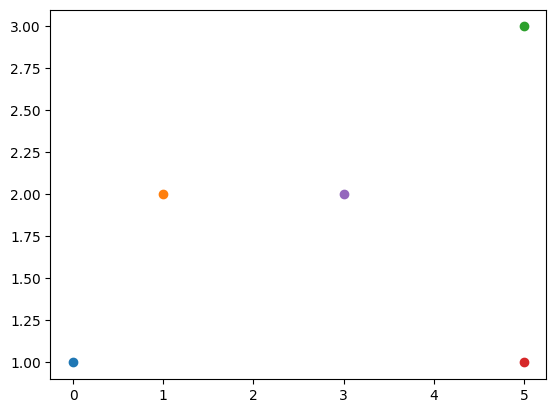

In [40]:
coordinates = [[0,1],[1,2],[5,3],[5,1],[3,2]]
points = [ Point(x[0],x[1]) for x in coordinates]

for p in points:
    p.plot()

1 3 0 5


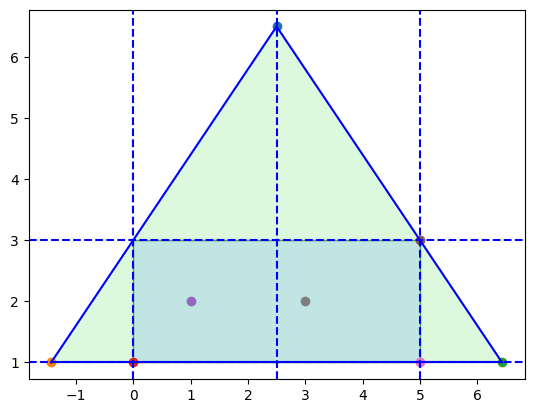

In [52]:
fig, ax = plt.subplots()
coordinates = [[0,1],[1,2],[5,3],[5,1],[3,2]]
points = [ Point(x[0],x[1]) for x in coordinates]

def calculateSuperTriangle(points):
    y_min = float('inf')
    y_max = float('-inf')
    x_min = float('inf')
    x_max = float('-inf')

    for p in points:
        y_min = min(p.y, y_min)
        y_max = max(p.y, y_max)
        x_min = min(p.x, x_min)
        x_max = max(p.x, x_max)

    x_len = abs(x_max - x_min)
    y_len = abs(y_max - y_min)

    if y_min == y_max or x_min == x_max or len(points) == 0:
        print("La figura forma una línea o está vacía")
        return

    # We draw a square using this maxes
    upper_left = Point(x_min, y_max)
    upper_right = Point(x_max, y_max)
    lower_right = Point(x_max, y_min)
    lower_left = Point(x_min, y_min)
    print(y_min, y_max, x_min, x_max)

    # We create a triangle, the upper point is in the middle of the upper edge of the rectangle, plus the 
    middle_point = Point(x_min+(x_max-x_min)/2, y_max+(y_len+x_len)/2)
    # f(x) = mx+b  -> y = mx+b
    m = (upper_left.y-middle_point.y)/(upper_left.x-middle_point.x)

    # b = y -mx
    b1 = upper_left.y - m * upper_left.x
    b2 = upper_right.y - (-m) * upper_right.x

    # x = (y-b)/m
    left_point = Point((y_min-b1)/m, y_min)
    right_point = Point((y_min-b2)/(-m), y_min)

    middle_point.plot()
    left_point.plot()
    right_point.plot()

    plt.plot([middle_point.x, left_point.x], [middle_point.y, left_point.y], color='blue', linestyle='-')
    plt.plot([middle_point.x, right_point.x], [middle_point.y, right_point.y], color='blue', linestyle='-')
    plt.plot([left_point.x, right_point.x], [left_point.y, right_point.y], color='blue', linestyle='-')

    plt.axhline(y=y_min, color='b', linestyle='--', label='ymin')
    plt.axhline(y=y_max, color='b', linestyle='--', label='ymax')
    plt.axvline(x=x_min, color='b', linestyle='--', label='xmin')
    plt.axvline(x=x_max, color='b', linestyle='--', label='xmax')

    plt.axvline(x=x_min+(x_max-x_min)/2, color='b', linestyle='--', label='xmax')

    triangle_points = [left_point,middle_point,right_point]
    triangle_coords=[(p.x,p.y) for p in triangle_points]
    triangle = Polygon(triangle_coords, closed=True, facecolor='lightgreen', edgecolor='darkgreen', alpha=0.3)

    rectangle_points = [upper_left, upper_right , lower_right, lower_left]
    rectangle_coords = [(p.x,p.y) for p in rectangle_points]
    rectangle = Polygon(rectangle_coords, closed=True, facecolor='lightblue', edgecolor='darkgreen', alpha=0.6)


    ax.add_patch(triangle)
    ax.add_patch(rectangle)


    for p in points:
        p.plot()

    plt.show()

calculateSuperTriangle(points)

0 10 0 10


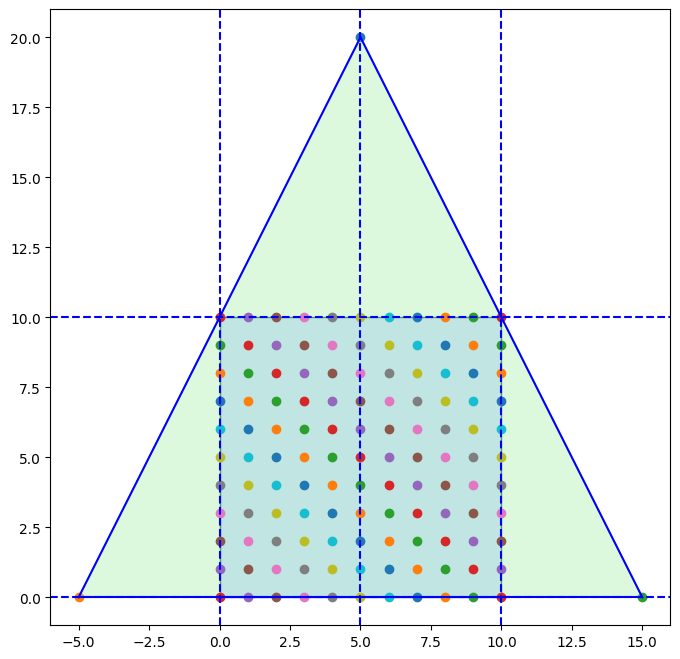

In [ ]:
import random

# Arreglo reproducible de 120 puntos aleatorios dentro de un cuadrado de 100 x 100
random.seed(42)
coordinates_large = [
    [random.uniform(0, 100), random.uniform(0, 100)]
    for _ in range(120)
]
points_large = [Point(x, y) for x, y in coordinates_large]

fig, ax = plt.subplots(figsize=(8, 8))
calculateSuperTriangle(points_large)
